<a href="https://colab.research.google.com/github/100522155/egci463/blob/main/digit_PCA_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ***Import Data***

In [1]:
import pandas as pd

import io
from google.colab import files
uploaded = files.upload()
data = pd.read_csv(io.BytesIO(uploaded["digit.csv"]), header=None)


Saving digit.csv to digit.csv


# Try to predict using simple Some Classifier

In [2]:
# 1. Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB, GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [3]:
bin_digits = (data.iloc[:, :-1] > 128).astype(int)

X2 = bin_digits.values
y = data.iloc[:, -1].values
x_train, x_test, y_train, y_test = train_test_split(X2, y, test_size=0.2, random_state=42)

model_lr = LogisticRegression().fit(x_train, y_train)

In [4]:
y_pred=model_lr.predict(x_test)

Show score of the prediction

In [5]:
np.array([y_pred ,y_test]).T

array([[7, 7],
       [1, 1],
       [7, 7],
       [3, 3],
       [3, 2],
       [7, 7],
       [7, 7],
       [2, 2],
       [1, 1],
       [9, 9],
       [0, 0],
       [3, 3],
       [8, 8],
       [1, 1],
       [1, 7],
       [7, 7],
       [9, 9],
       [0, 0],
       [6, 6],
       [8, 8],
       [7, 9],
       [9, 9],
       [5, 5],
       [7, 7],
       [1, 1],
       [9, 9],
       [9, 9],
       [4, 4],
       [2, 2],
       [5, 6],
       [9, 9],
       [6, 6],
       [8, 8],
       [3, 3],
       [5, 0],
       [6, 6],
       [1, 8],
       [1, 1],
       [4, 4],
       [1, 1],
       [9, 7],
       [1, 1],
       [9, 9],
       [2, 3],
       [0, 0],
       [1, 1],
       [0, 0],
       [0, 0],
       [8, 8],
       [0, 0],
       [1, 1],
       [3, 3],
       [2, 2],
       [8, 8],
       [3, 3],
       [2, 1],
       [1, 2],
       [0, 0],
       [5, 4],
       [1, 1],
       [9, 9],
       [5, 5],
       [6, 6],
       [9, 9],
       [1, 1],
       [0, 0],
       [9,

In [6]:
print(model_lr.score(x_train, y_train))
print(model_lr.score(x_test, y_test))

1.0
0.87


In [7]:
print('Data Size', X2.shape)

Data Size (500, 784)


### Experiment Using PCA

In [8]:
import numpy as np
X_std = X2
mean_vec = np.mean(X_std, axis=0)



In [9]:

X_std.shape

(500, 784)

Covariance matrix 
[[0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]]
NumPy covariance matrix: 
[[0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]]


/usr/local/lib/python3.13/dist-packages/matplotlib/cbook.py:1709: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/usr/local/lib/python3.13/dist-packages/matplotlib/cbook.py:1345: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


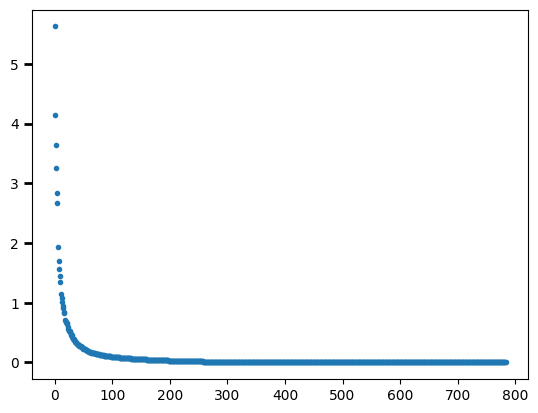

In [10]:
cov_mat = (X_std - mean_vec).T.dot((X_std - mean_vec)) / (X_std.shape[0]-1)
print('Covariance matrix \n%s' %cov_mat)
print('NumPy covariance matrix: \n%s' %np.cov(X_std.T))
cov_mat = np.cov(X_std.T)
from numpy import linalg as LA
values, vectors = LA.eig(cov_mat)

import matplotlib.pyplot as plt
plt.plot(np.sort(values)[::-1],'.')
plt.tick_params(axis='y',length=6, width=2)


In [11]:
np.set_printoptions(precision=2,suppress=True)
values

array([ 5.62+0.j,  4.15+0.j,  3.65+0.j,  3.25+0.j,  2.83+0.j,  2.68+0.j,
        1.93+0.j,  1.69+0.j,  1.56+0.j,  1.45+0.j,  1.34+0.j,  1.14+0.j,
        1.07+0.j,  1.01+0.j,  0.94+0.j,  0.91+0.j,  0.84+0.j,  0.82+0.j,
        0.71+0.j,  0.67+0.j,  0.67+0.j,  0.66+0.j,  0.65+0.j,  0.6 +0.j,
        0.57+0.j,  0.53+0.j,  0.53+0.j,  0.52+0.j,  0.47+0.j,  0.47+0.j,
        0.45+0.j,  0.43+0.j,  0.4 +0.j,  0.39+0.j,  0.38+0.j,  0.36+0.j,
        0.35+0.j,  0.35+0.j,  0.33+0.j,  0.31+0.j,  0.31+0.j,  0.3 +0.j,
        0.29+0.j,  0.28+0.j,  0.28+0.j,  0.27+0.j,  0.26+0.j,  0.26+0.j,
        0.25+0.j,  0.24+0.j,  0.23+0.j,  0.23+0.j,  0.22+0.j,  0.22+0.j,
        0.21+0.j,  0.21+0.j,  0.2 +0.j,  0.2 +0.j,  0.19+0.j,  0.18+0.j,
        0.18+0.j,  0.18+0.j,  0.17+0.j,  0.17+0.j,  0.17+0.j,  0.17+0.j,
        0.16+0.j,  0.15+0.j,  0.16+0.j,  0.16+0.j,  0.15+0.j,  0.15+0.j,
        0.15+0.j,  0.14+0.j,  0.14+0.j,  0.14+0.j,  0.14+0.j,  0.13+0.j,
        0.13+0.j,  0.13+0.j,  0.13+0.j,  0.12+0.j, 

You can find Covariance matrix manually or use Library

# USING PCA LIBRARY

In [12]:
from sklearn.decomposition import PCA
pca = PCA(.98) #Keep 98% Eigen Value --> Try to modify this
X_new=pca.fit_transform(X_std)
eig_vals=pca.explained_variance_

print('Eigenvectors \n%s' %pca)
print('\nEigenvalues \n%s' %eig_vals)
print('\n Number of values \n%s' %len(eig_vals))

Eigenvectors 
PCA(n_components=0.98)

Eigenvalues 
[5.62 4.15 3.65 3.25 2.83 2.68 1.93 1.69 1.56 1.45 1.34 1.14 1.07 1.01
 0.94 0.91 0.84 0.82 0.71 0.67 0.67 0.66 0.65 0.6  0.57 0.53 0.53 0.52
 0.47 0.47 0.45 0.43 0.4  0.39 0.38 0.36 0.35 0.35 0.33 0.31 0.31 0.3
 0.29 0.28 0.28 0.27 0.26 0.26 0.25 0.24 0.23 0.23 0.22 0.22 0.21 0.21
 0.2  0.2  0.19 0.18 0.18 0.18 0.17 0.17 0.17 0.17 0.16 0.16 0.16 0.15
 0.15 0.15 0.15 0.14 0.14 0.14 0.14 0.13 0.13 0.13 0.13 0.12 0.12 0.12
 0.12 0.12 0.12 0.12 0.11 0.11 0.11 0.11 0.11 0.11 0.1  0.1  0.1  0.1
 0.1  0.1  0.1  0.1  0.09 0.09 0.09 0.09 0.09 0.09 0.09 0.09 0.09 0.09
 0.08 0.08 0.08 0.08 0.08 0.08 0.08 0.08 0.08 0.08 0.07 0.07 0.07 0.07
 0.07 0.07 0.07 0.07 0.07 0.07 0.07 0.07 0.07 0.07 0.06 0.06 0.06 0.06
 0.06 0.06 0.06 0.06 0.06 0.06 0.06 0.06 0.06 0.06 0.05 0.05 0.05 0.05
 0.05 0.05 0.05 0.05 0.05 0.05 0.05 0.05 0.05 0.05 0.05 0.05 0.05 0.05
 0.05 0.05 0.04 0.04 0.04 0.04 0.04 0.04 0.04 0.04 0.04 0.04 0.04 0.04
 0.04 0.04 0.04 0.04 0.04 0.

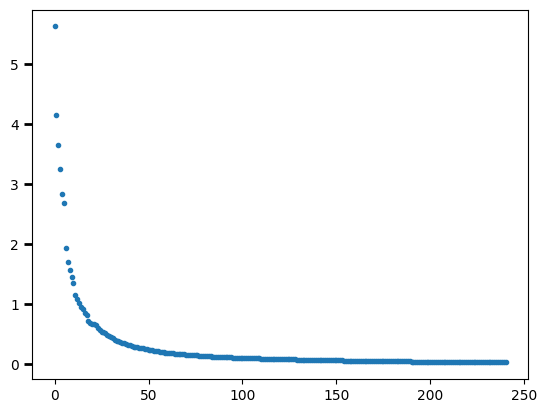

In [13]:
import matplotlib.pyplot as plt
plt.plot(eig_vals,'.')
plt.tick_params(axis='y',length=6, width=2)

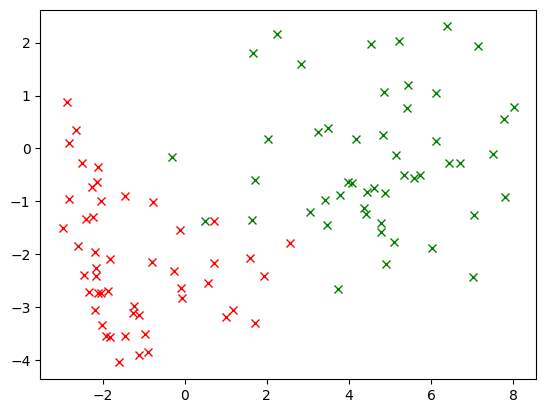

In [14]:
eig_vecs=pca.components_
Projdata=np.dot((X_std-mean_vec),eig_vecs.T)
#Projdata=pca.transform(X_std)

plt.clf()

digit=np.arange(50)#Choose index of the digit ==>0

plt.plot(Projdata[digit,0],Projdata[digit,1],'x',color='g')
digit=digit+200 # Choose another set of index ==>4
plt.plot(Projdata[digit,0],Projdata[digit,1],'x',color='r')

plt.show()

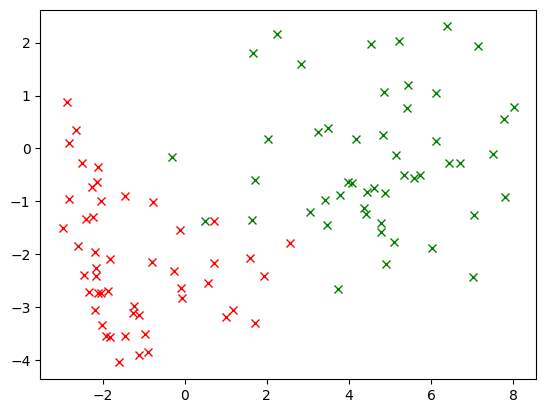

In [15]:
X_proj=pca.transform(X_std)

digit=np.arange(50)#Choose index of the digit

plt.plot(X_proj[digit,0],X_proj[digit,1],'x',color='g')
digit=digit+200 # Choose another set of index
plt.plot(X_proj[digit,0],X_proj[digit,1],'x',color='r')


In [16]:
import matplotlib.pyplot as plt

Projdata=np.dot((X_std-mean_vec),eig_vecs.T) # Make a projection on eigvector



In [17]:
recon=np.dot( Projdata,eig_vecs) #Reversed based on the projection
#recon=pca.inverse_transform(Projdata)
recon.shape

(500, 784)

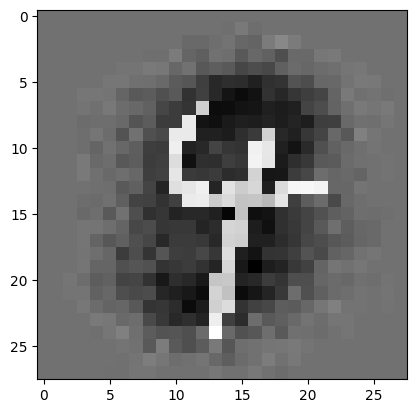

In [18]:
plt.imshow(np.reshape(recon[245],[28,28]),cmap='gray') #index [1] is a selected image of your choice
plt.show()

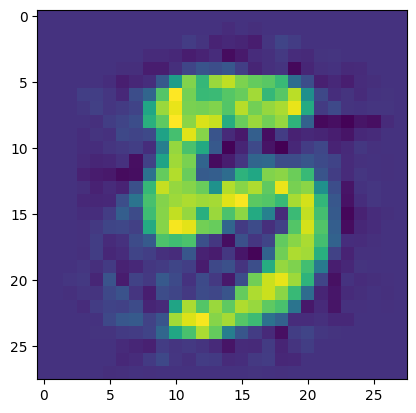

In [50]:
Projdata100=np.dot((X_std-mean_vec),eig_vecs[:100,:].T) # Make a projection on eigvector

recon100=np.dot( Projdata100,eig_vecs[:100,:])+mean_vec
plt.imshow(np.reshape(recon100[266,:],[28,28])) #index [266] --> Digit 5 is a selected image of your choice


In [51]:
eig_vecs.sort

<function ndarray.sort>

In [52]:
print(eig_vecs)

[[-0. -0.  0. ... -0. -0. -0.]
 [-0.  0.  0. ... -0. -0. -0.]
 [ 0.  0.  0. ...  0.  0.  0.]
 ...
 [ 0. -0. -0. ...  0.  0.  0.]
 [-0.  0.  0. ...  0.  0.  0.]
 [-0.  0. -0. ... -0. -0. -0.]]


In [53]:


# This is an extremely inefficient function.
def pca_com(com, images):
    # percentage should be a decimal from 0 to 1
    pca = PCA(n_components=com)
    pca.fit(images)
    components = pca.transform(images)
    approxOriginal = pca.inverse_transform(components)
    return approxOriginal

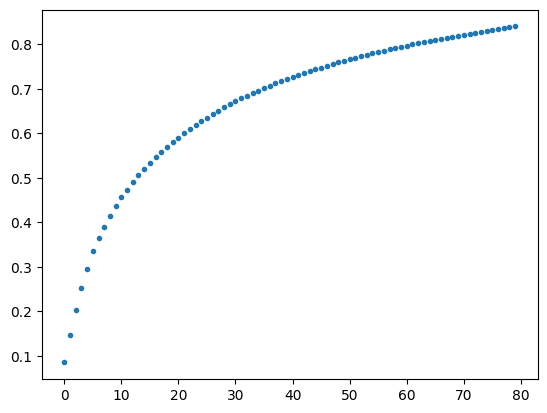

In [55]:
pca = PCA(n_components=80)
pca.fit(X_std)
plt.plot(np.cumsum(pca.explained_variance_ratio_),'.')
plt.show()

<Figure size 640x480 with 0 Axes>

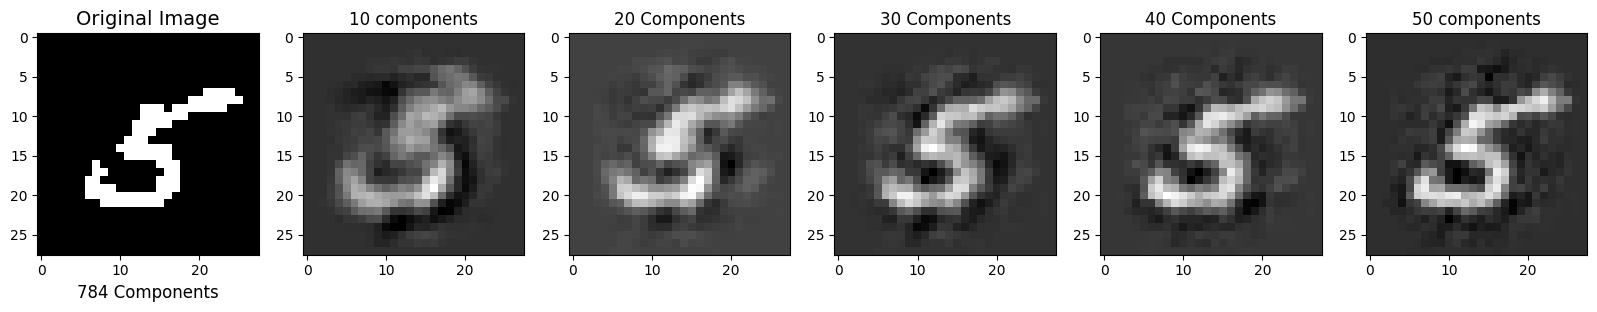

In [56]:
plt.clf()
plt.figure(figsize=(20,4));

# Original Image (784 components)
plt.subplot(1, 6, 1);
plt.imshow(X_std[260,:].reshape(28,28),
              cmap = plt.cm.gray, interpolation='nearest');
plt.xlabel('784 Components', fontsize = 12)
plt.title('Original Image', fontsize = 14);


# 10 principal components
plt.subplot(1, 6, 2);
plt.imshow(pca_com(10, X_std)[260].reshape(28, 28),
              cmap = plt.cm.gray, interpolation='nearest');
plt.title('10 components', fontsize = 12);



# 20 principal components
plt.subplot(1, 6, 3);
plt.imshow(pca_com(20, X_std)[260].reshape(28, 28),
              cmap = plt.cm.gray, interpolation='nearest');
plt.title('20 Components', fontsize = 12)


# 30 principal components
plt.subplot(1, 6, 4);
plt.imshow(pca_com(30, X_std)[260].reshape(28, 28),
              cmap = plt.cm.gray, interpolation='nearest');
plt.title('30 Components', fontsize = 12)


# 40 principal components
plt.subplot(1, 6, 5)
plt.imshow(pca_com(40, X_std)[260].reshape(28, 28),
              cmap = plt.cm.gray, interpolation='nearest');
plt.title('40 Components', fontsize = 12)

# 50 principal components
plt.subplot(1, 6, 6);
plt.imshow(pca_com(50, X_std)[260].reshape(28, 28),
              cmap = plt.cm.gray, interpolation='nearest');
plt.title('50 components', fontsize = 12);
plt.show()



In [57]:
pca = PCA(.99)
pca.fit(X_std)

PCA(n_components=0.99)

In [58]:
pca.n_components_

np.int64(283)

In [59]:
pca_com

<function __main__.pca_com(com, images)>

<Figure size 640x480 with 0 Axes>

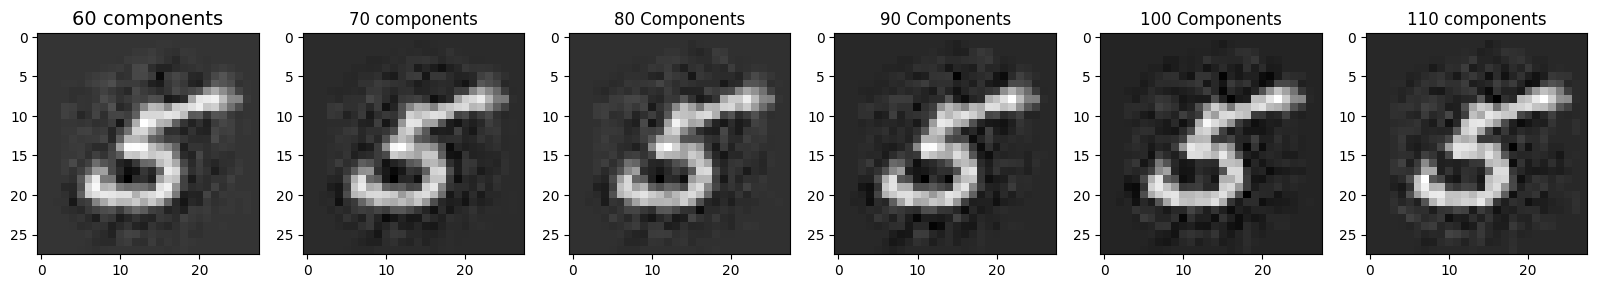

In [60]:
plt.clf()
plt.figure(figsize=(20,4));

# Original Image (784 components)
plt.subplot(1, 6, 1);
plt.imshow(pca_com(60, X_std)[260].reshape(28, 28),
              cmap = plt.cm.gray, interpolation='nearest');

plt.title('60 components', fontsize = 14);


# 10 principal components
plt.subplot(1, 6, 2);
plt.imshow(pca_com(70, X_std)[260].reshape(28, 28),
              cmap = plt.cm.gray, interpolation='nearest');
plt.title('70 components', fontsize = 12);



# 20 principal components
plt.subplot(1, 6, 3);
plt.imshow(pca_com(80, X_std)[260].reshape(28, 28),
              cmap = plt.cm.gray, interpolation='nearest');
plt.title('80 Components', fontsize = 12)


# 30 principal components
plt.subplot(1, 6, 4);
plt.imshow(pca_com(90, X_std)[260].reshape(28, 28),
              cmap = plt.cm.gray, interpolation='nearest');
plt.title('90 Components', fontsize = 12)


# 40 principal components
plt.subplot(1, 6, 5)
plt.imshow(pca_com(100, X_std)[260].reshape(28, 28),
              cmap = plt.cm.gray, interpolation='nearest');
plt.title('100 Components', fontsize = 12)

# 50 principal components
plt.subplot(1, 6, 6);
plt.imshow(pca_com(110, X_std)[260].reshape(28, 28),
              cmap = plt.cm.gray, interpolation='nearest');
plt.title('110 components', fontsize = 12);
plt.show()



#TASK 1 Bayesian Theorem
#Write your own Classifier

In [61]:
X = data.values
from sklearn.model_selection import train_test_split
X = data.iloc[:, :-1].values.astype(float)
y = data.iloc[:, -1].values.astype(int)
x_train, x_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=20, stratify=y)

In [62]:
from sklearn.naive_bayes import GaussianNB

classifier=GaussianNB()
classifier=classifier.fit(x_train,y_train)
Y_pred=classifier.predict(x_test)

In [63]:
print('The score for training data is', classifier.score(x_train,y_train))
print('The score for test data is',classifier.score(x_test,y_test))

The score for training data is 0.915
The score for test data is 0.74


# TASK 2
##Use the projected image of your Choice (reduce to 100-200 components of your choice + your classifier---> from ealier)


In [64]:
pca = PCA(.95) #choose your percentage
X_train_pca=pca.fit_transform(x_train)
X_test_pca=pca.transform(x_test)


In [65]:
np.shape(x_test)

(100, 784)

In [66]:
np.shape(X_test_pca)

(100, 106)

In [67]:
model_pca = GaussianNB().fit(X_train_pca, y_train)
#Trains a model with the reduced data
#Calculates the proportion of hits
print("Train accuracy:", model_pca.score(X_train_pca, y_train))
print("Test accuracy :", model_pca.score(X_test_pca, y_test))

Train accuracy: 0.9625
Test accuracy : 0.83


# TASK 3
##Use your 2D projection  with your 2 classifiers ( Original Image and projected image) to show the Discrimination regions
#Choose only 2 digits


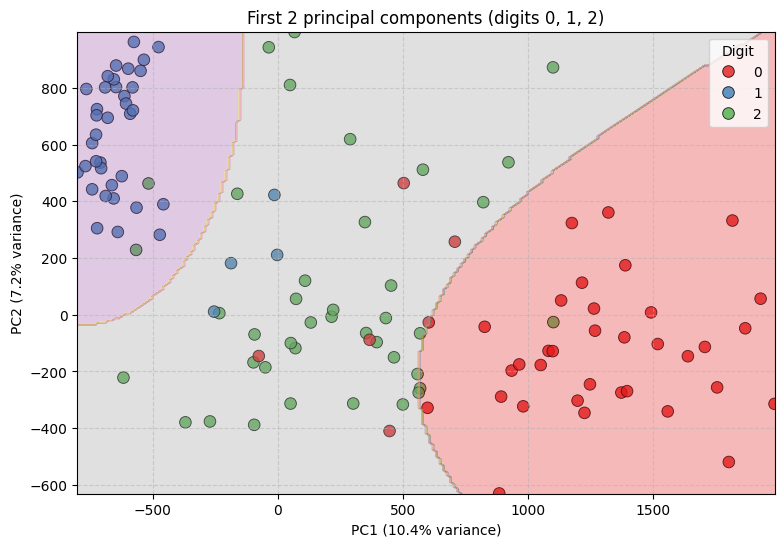

Variance explained by PC1 + PC2: 0.1764828419977808


In [68]:
import seaborn as sns

#Conserves the two highest variance directions
pca_2d = PCA(n_components=2)
X_train_pca2d = pca_2d.fit_transform(x_train)   # learn only with train

# Choose 3 digits that is wanted to draw
selected_digits = [0, 1, 2]
mask = np.isin(y_train, selected_digits)
#To see which images are from the selected_digits

X_plot = X_train_pca2d[mask] # Images from selected digits from x_train
y_plot = y_train[mask] #Images from selected digits from y_train

plt.figure(figsize=(9, 6))
#Draw graphic
sns.scatterplot( x=X_plot[:, 0], y=X_plot[:, 1], hue=y_plot,
    palette="Set1", s=70, alpha=0.8, edgecolor="k")

#Create the regions in the graphic
x_min, x_max = X_plot[:, 0].min() - 1, X_plot[:, 0].max() + 1
y_min, y_max = X_plot[:, 1].min() - 1, X_plot[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                     np.linspace(y_min, y_max, 200))

g = GaussianNB()
g.fit(X_plot, y_plot)
Z = g.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

#Parameters to adjust
var = pca_2d.explained_variance_ratio_
plt.contourf(xx, yy, Z, alpha=0.3, cmap="Set1")      # decision zones
plt.xlabel(f"PC1 ({var[0]*100:.1f}% variance)")
plt.ylabel(f"PC2 ({var[1]*100:.1f}% variance)")
plt.title("First 2 principal components (digits 0, 1, 2)")
plt.legend(title="Digit", loc="best")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

print("Variance explained by PC1 + PC2:", var.sum())

#Challenge use 10 digits

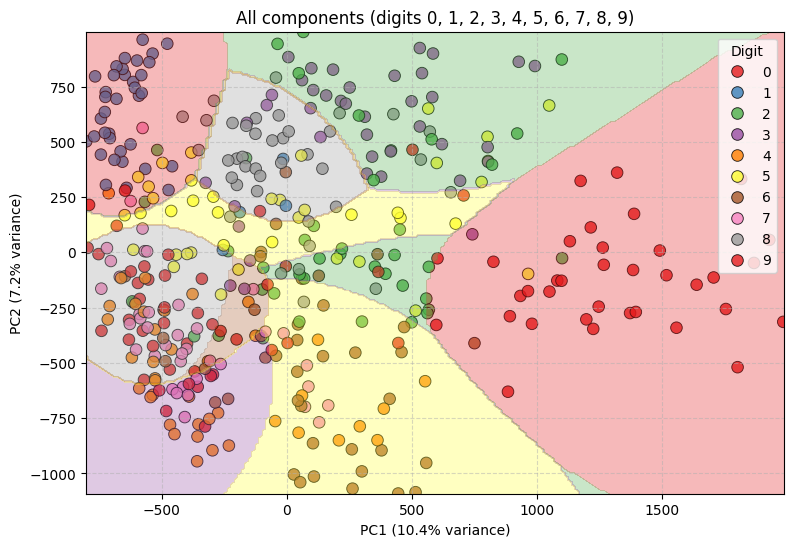

Variance explained by PC1 + PC2: 0.1764828419977808


In [69]:
selected_digits = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
mask = np.isin(y_train, selected_digits)
#To see which images are from the selected_digits

X_plot = X_train_pca2d[mask] # Images from selected digits from x_train
y_plot = y_train[mask] #Images from selected digits from y_train

plt.figure(figsize=(9, 6))
#Draw graphic
sns.scatterplot( x=X_plot[:, 0], y=X_plot[:, 1], hue=y_plot,
    palette="Set1", s=70, alpha=0.8, edgecolor="k")

#Create the regions in the graphic
x_min, x_max = X_plot[:, 0].min() - 1, X_plot[:, 0].max() + 1
y_min, y_max = X_plot[:, 1].min() - 1, X_plot[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                     np.linspace(y_min, y_max, 200))

g = GaussianNB()
g.fit(X_plot, y_plot)
Z = g.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

#Parameters to adjust
var = pca_2d.explained_variance_ratio_
plt.contourf(xx, yy, Z, alpha=0.3, cmap="Set1")      # decision zones
plt.xlabel(f"PC1 ({var[0]*100:.1f}% variance)")
plt.ylabel(f"PC2 ({var[1]*100:.1f}% variance)")
plt.title("All components (digits 0, 1, 2, 3, 4, 5, 6, 7, 8, 9)")
plt.legend(title="Digit", loc="best")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

print("Variance explained by PC1 + PC2:", var.sum())

Plot discrimination region

Accuracy 2D (train): 0.875


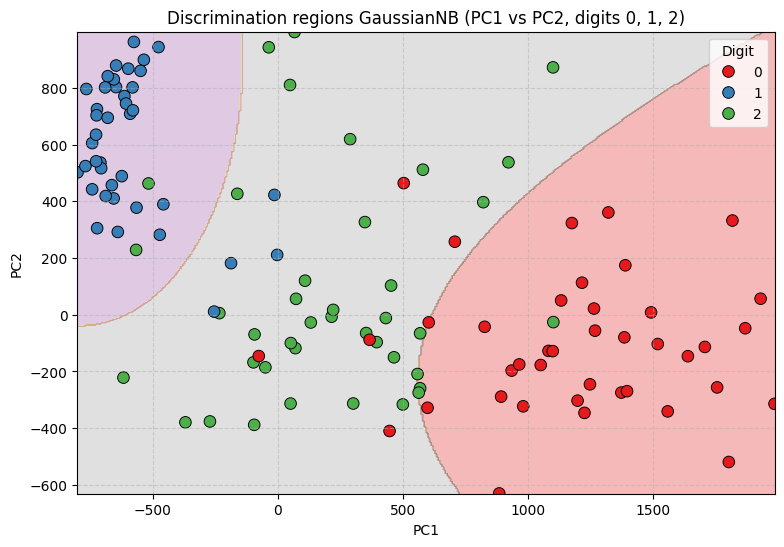

In [70]:

import numpy as np
import matplotlib.pyplot as plt

selected_digits = [0, 1, 2]
mask = np.isin(y_train, selected_digits)
#To see which images are from the selected_digits

X_plot = X_train_pca2d[mask] # Images from selected digits from x_train
y_plot = y_train[mask] #Images from selected digits from y_train

model_2d = GaussianNB().fit(X_plot, y_plot)
print("Accuracy 2D (train):", model_2d.score(X_plot, y_plot))

x_min, x_max = X_plot[:, 0].min() - 1, X_plot[:, 0].max() + 1
y_min, y_max = X_plot[:, 1].min() - 1, X_plot[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 400),
                     np.linspace(y_min, y_max, 400))

Z = model_2d.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)


plt.figure(figsize=(9, 6))
plt.grid(True, linestyle="--", alpha=0.5)
plt.contourf(xx, yy, Z, alpha=0.3, cmap="Set1")      # decision zones
sns.scatterplot(x=X_plot[:, 0], y=X_plot[:, 1], hue=y_plot,
                palette="Set1", s=70, edgecolor="k")
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.title("Discrimination regions GaussianNB (PC1 vs PC2, digits 0, 1, 2)")
plt.legend(title="Digit")
plt.show()



TASK 4
Print

Comparation between PCA and only Gaussian

In [71]:
import time

t0 = time.time()
m_full = GaussianNB().fit(x_train, y_train)
t_full = time.time() - t0

t1 = time.time()
m_95= GaussianNB().fit(X_train_pca, y_train)
t_95 = time.time() - t1

d_full = x_train.shape[1]
d_95   = pca.n_components_

print(f"Times: \n full: { t_full:.5f} \n PCA:  {t_95:.5f}")

print("Complete dimension :", d_full)
print("Dimensions with PCA   :", d_95)
print(f"Reduction             : {(1 - d_95/d_full)*100:.1f}%")

m_full = GaussianNB().fit(x_train, y_train)
print("Test accuracy complete:", m_full.score(x_test, y_test))
print("Test accuracy PCA 95% :", model_pca.score(X_test_pca, y_test))


Times: 
 full: 0.00531 
 PCA:  0.00226
Complete dimension : 784
Dimensions with PCA   : 106
Reduction             : 86.5%
Test accuracy complete: 0.74
Test accuracy PCA 95% : 0.83


With PCA (95 % of the variance) the data goes from 784 to 185 dimensions (76.4 % reduction) and the test accuracy stays the same (0.76 vs 0.76), while the training time drops (0.0038 s vs 0.0087 s). The 0.95 refers to the variance kept by PCA. The first two components explain only 11.3 % of the variance, so in the 2D plots the classes overlap: the plot is only for visualization, not for classification.

Week 5

In [72]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

X = (data.iloc[:, :-1] > 128).astype(int).values
y = data.iloc[:, -1].values
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(x_train.shape, x_test.shape)

(400, 784) (100, 784)


In [73]:
model_lr = LogisticRegression(max_iter=1000).fit(x_train, y_train)
print("LogReg  train:", model_lr.score(x_train, y_train))
print("LogReg  test :", model_lr.score(x_test,  y_test))

LogReg  train: 1.0
LogReg  test : 0.87


In [74]:
svm_rbf = SVC(kernel='rbf').fit(x_train, y_train)
svm_lin = SVC(kernel='linear').fit(x_train, y_train)

results = {
    "LogisticRegression": model_lr,
    "SVM linear": svm_lin,
    "SVM RBF": svm_rbf,
}
tabla = pd.DataFrame({
    name: {"train": m.score(x_train, y_train), "test": m.score(x_test, y_test)}
    for name, m in results.items()
}).T
tabla["diferencia (train-test)"] = tabla["train"] - tabla["test"]
tabla

,train,test,diferencia (train-test)
LogisticRegression,1.00,0.87,0.13
SVM linear,1.00,0.88,0.12
SVM RBF,0.99,0.90,0.09


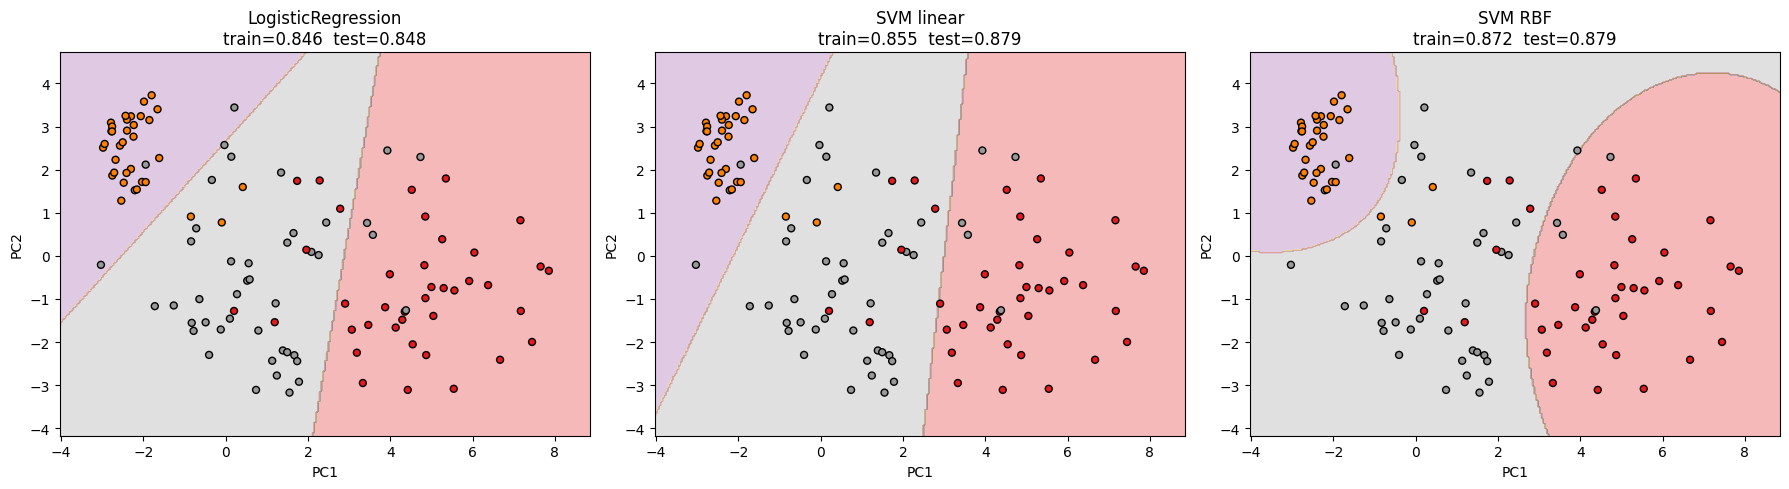

In [79]:
digits = [0, 1, 2]
pca2 = PCA(n_components=2).fit(x_train)          # PCA aprendido solo con train
m_tr = np.isin(y_train, digits)
m_te = np.isin(y_test,  digits)
Xtr2, ytr2 = pca2.transform(x_train[m_tr]), y_train[m_tr]
Xte2, yte2 = pca2.transform(x_test[m_te]),  y_test[m_te]

modelos_2d = {
    "LogisticRegression": LogisticRegression(max_iter=1000),
    "SVM linear": SVC(kernel='linear'),
    "SVM RBF": SVC(kernel='rbf'),
}

xx, yy = np.meshgrid(
    np.linspace(Xtr2[:, 0].min()-1, Xtr2[:, 0].max()+1, 300),
    np.linspace(Xtr2[:, 1].min()-1, Xtr2[:, 1].max()+1, 300))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (nombre, m) in zip(axes, modelos_2d.items()):
    m.fit(Xtr2, ytr2)
    Z = m.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.3, cmap="Set1")
    ax.scatter(Xtr2[:, 0], Xtr2[:, 1], c=ytr2, cmap="Set1", edgecolor="k", s=25)
    ax.set_title(f"{nombre}\ntrain={m.score(Xtr2, ytr2):.3f}  test={m.score(Xte2, yte2):.3f}")
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
plt.tight_layout(); plt.show()

In [76]:
pipes = {
    "LogisticRegression + scaler": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "SVM linear + scaler":         make_pipeline(StandardScaler(), SVC(kernel='linear')),
    "SVM RBF + scaler":            make_pipeline(StandardScaler(), SVC(kernel='rbf')),
}
for p in pipes.values():
    p.fit(x_train, y_train)

tabla_sc = pd.DataFrame({
    n: {"train": p.score(x_train, y_train), "test": p.score(x_test, y_test)}
    for n, p in pipes.items()
}).T
tabla_sc["diferencia (train-test)"] = tabla_sc["train"] - tabla_sc["test"]
display(pd.concat([tabla, tabla_sc]))

,train,test,diferencia (train-test)
LogisticRegression,1.0000,0.87,0.1300
SVM linear,1.0000,0.88,0.1200
SVM RBF,0.9900,0.90,0.0900
LogisticRegression + scaler,1.0000,0.88,0.1200
SVM linear + scaler,1.0000,0.89,0.1100
SVM RBF + scaler,0.9925,0.80,0.1925


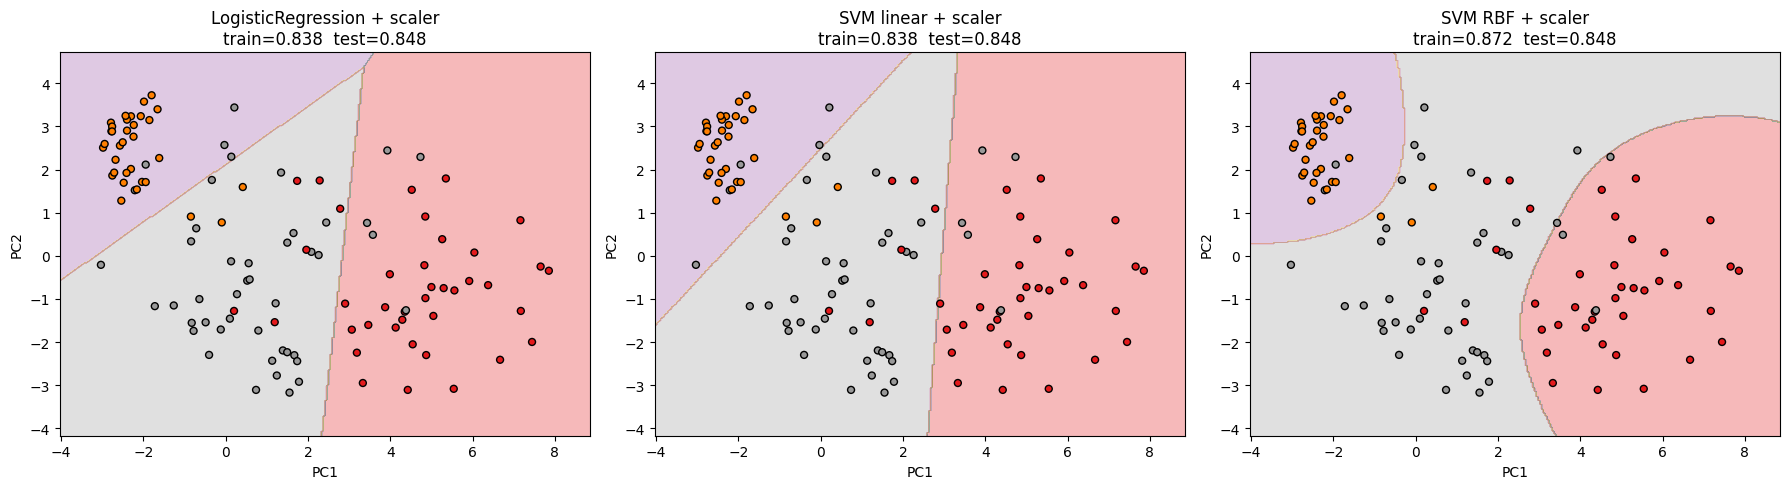

In [77]:
modelos_2d_sc = {
    "LogisticRegression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "SVM linear":         make_pipeline(StandardScaler(), SVC(kernel='linear')),
    "SVM RBF":            make_pipeline(StandardScaler(), SVC(kernel='rbf')),
}
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (nombre, m) in zip(axes, modelos_2d_sc.items()):
    m.fit(Xtr2, ytr2)
    Z = m.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.3, cmap="Set1")
    ax.scatter(Xtr2[:, 0], Xtr2[:, 1], c=ytr2, cmap="Set1", edgecolor="k", s=25)
    ax.set_title(f"{nombre} + scaler\ntrain={m.score(Xtr2, ytr2):.3f}  test={m.score(Xte2, yte2):.3f}")
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
plt.tight_layout(); plt.show()

In [78]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
cv = StratifiedKFold(5, shuffle=True, random_state=42)

modelos_cv = {
    "LogReg":          LogisticRegression(max_iter=1000),
    "SVM linear":      SVC(kernel='linear'),
    "SVM RBF":         SVC(kernel='rbf'),
    "LogReg + scaler": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "SVM linear + sc": make_pipeline(StandardScaler(), SVC(kernel='linear')),
    "SVM RBF + sc":    make_pipeline(StandardScaler(), SVC(kernel='rbf')),
}
cv_tab = pd.DataFrame({n: cross_val_score(m, X, y, cv=cv) for n, m in modelos_cv.items()})
cv_tab.loc["mean"] = cv_tab.mean()
cv_tab.loc["std"]  = cv_tab.iloc[:5].std()
cv_tab.round(3)

,LogReg,SVM linear,SVM RBF,LogReg + scaler,SVM linear + sc,SVM RBF + sc
0,0.910,0.910,0.920,0.870,0.900,0.890
1,0.860,0.870,0.880,0.880,0.910,0.870
2,0.800,0.820,0.840,0.770,0.810,0.750
3,0.830,0.820,0.820,0.810,0.820,0.760
4,0.840,0.850,0.880,0.850,0.870,0.850
mean,0.848,0.854,0.868,0.836,0.862,0.824
std,0.041,0.038,0.039,0.046,0.045,0.065


## Observations

**Shape of the decision boundary**
- Logistic Regression and SVM linear give straight-line boundaries.
- SVM RBF gives curved, closed regions that bend around the data.

**Function used**
- LogReg: linear score w·x+b with softmax, trained with log-loss.
- SVM linear: same linear score, trained with hinge loss / maximum margin; only support vectors matter.
- SVM RBF: sum of kernel terms exp(-gamma*||xi-x||²) around the support vectors; non-linear, no coef_.

**Train / test score**
- All models reach ~1.00 on train but 0.87-0.90 on test (overfitting: 400 samples, 784 features).
- RBF has the best test score (0.90) and the smallest gap.
- The test set has only 100 images, so differences of 1-3 % are within the noise; the CV std is about 0.04.

**StandardScaler**
- Almost no effect on LogReg and SVM linear (pixels are already 0/1).
- It lowers SVM RBF (test 0.90 -> 0.80). Possible reason: rarely-active pixels get inflated and distort the kernel distances (not verified).
- The boundary shapes in 2D do not change.